# ДЗ №1. Анализ временного ряда продаж

Выполнил студент 1 курса ИПИИ Кожемякин Григорий

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

plt.rcParams["figure.figsize"] = (12,4)
plt.rcParams["axes.grid"] = True

In [2]:
def load_data(path):
    df = pd.read_excel(
        path,
        dtype={"StockCode": "string", "InvoiceNo": "string"},
    )
    df["InvoiceDate"] = pd.to_datetime(
        df["InvoiceDate"], errors="coerce"
    )
    return df


def inspect_data(df):
    print(f"Размер таблицы: {df.shape[0]:,} строк, {df.shape[1]} столбцов")

    print("\nПервые строки:")
    display(df.head())

    print("\nТипы данных и пропуски:")
    display(
        pd.DataFrame({
            "dtype": df.dtypes,
            "missing": df.isna().sum(),
            "missing_pct": df.isna().mean().mul(100).round(2),
        })
    )

    print("\nПериод наблюдений:")
    print(df["InvoiceDate"].min(), "—", df["InvoiceDate"].max())

    print("\nКоличество полных дубликатов:", df.duplicated().sum())


df = load_data(Path("Online Retail.xlsx"))
inspect_data(df)

Размер таблицы: 541,909 строк, 8 столбцов

Первые строки:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Типы данных и пропуски:


,dtype,missing,missing_pct
InvoiceNo,string[python],0,0.00
StockCode,string[python],0,0.00
Description,object,1454,0.27
Quantity,int64,0,0.00
InvoiceDate,datetime64[ns],0,0.00
UnitPrice,float64,0,0.00
CustomerID,float64,135080,24.93
Country,object,0,0.00



Период наблюдений:
2010-12-01 08:26:00 — 2011-12-09 12:50:00

Количество полных дубликатов: 5268


In [3]:
def get_product_candidates(df, top_n=20):
    mask = (
        df["StockCode"].ne("85123A")
        & df["Quantity"].gt(0)
        & df["UnitPrice"].gt(0)
        & ~df["InvoiceNo"].str.upper().str.startswith("C", na=False)
    )

    sales = df.loc[mask].copy()
    sales["date"] = sales["InvoiceDate"].dt.normalize()

    candidates = (
        sales.groupby("StockCode")
        .agg(
            description=("Description", "first"),
            active_days=("date", "nunique"),
            n_invoices=("InvoiceNo", "nunique"),
            units=("Quantity", "sum"),
            first_sale=("date", "min"),
            last_sale=("date", "max"),
        )
        .sort_values(
            ["active_days", "n_invoices"],
            ascending=False,
        )
    )

    return candidates.head(top_n)


candidates = get_product_candidates(df)
display(candidates)

,description,active_days,n_invoices,units,first_sale,last_sale
StockCode,,,,,,
22423,REGENCY CAKESTAND 3 TIER,301,1988,13879,2010-12-01,2011-12-09
85099B,JUMBO BAG RED RETROSPOT,300,2089,48474,2010-12-01,2011-12-09
84879,ASSORTED COLOUR BIRD ORNAMENT,300,1455,36461,2010-12-01,2011-12-09
20725,LUNCH BAG RED RETROSPOT,298,1565,19553,2010-12-01,2011-12-09
21212,PACK OF 72 RETROSPOT CAKE CASES,298,1320,36419,2010-12-01,2011-12-09
22457,NATURAL SLATE HEART CHALKBOARD,297,1249,9172,2010-12-01,2011-12-09
22960,JAM MAKING SET WITH JARS,295,1132,8706,2010-12-01,2011-12-09
47566,PARTY BUNTING,294,1685,18295,2010-12-03,2011-12-09
22197,SMALL POPCORN HOLDER,294,1392,56921,2010-12-01,2011-12-09


### Отбор кандидатов и выбор товара

Для выбора товара рассмотрены операции без отмен. В датасете Online Retail отменённые операции обозначаются номером `InvoiceNo`, начинающимся с `C`. Товар `85123A` исключён согласно условию ДЗ. Ограничения примененили только для формирования списка кандидатов.

Кандидаты отсортированы по числу дней с продажами, затем по числу уникальных документов. Это позволяет выбрать регулярно продающийся товар,
для которого доступна достаточно продолжительная история наблюдений.

Для анализа выбран товар **22384 - LUNCH BAG PINK POLKADOT** (розовый ланчбокс в горошек). В отобранных операциях он встречается в 292 разных днях и 1090 документах; суммарное количество составляет 10 515 единиц. Продажи наблюдаются с 1 декабря 2010 года по 9 декабря 2011 года - от начала до конца периода датасета.

### Выбор показателя

Показатель для анализа — **количество проданных единиц товара за период**. Он имеет понятную интерпретацию и позволяет исследовать физический объём
продаж без прямого влияния изменений цены, характерного для выручки. 

In [4]:
PRODUCT_CODE = "22384"

def inspect_product(df, product_code):
    product = df.loc[
        df["StockCode"].eq(product_code)
    ].copy()

    cancelled = (
        product["InvoiceNo"]
        .str.upper()
        .str.startswith("C", na=False)
    )

    summary = pd.Series({
        "Всего строк": len(product),
        "Полных дубликатов": product.duplicated().sum(),
        "Строк с отменами": cancelled.sum(),
        "Строк с Quantity < 0": product["Quantity"].lt(0).sum(),
        "Строк с Quantity = 0": product["Quantity"].eq(0).sum(),
        "Строк с UnitPrice <= 0": product["UnitPrice"].le(0).sum(),
        "Пропусков Quantity": product["Quantity"].isna().sum(),
        "Пропусков UnitPrice": product["UnitPrice"].isna().sum(),
        "Пропусков даты": product["InvoiceDate"].isna().sum(),
    })

    display(summary.to_frame("Количество"))

    print("Варианты описания товара:")
    display(product["Description"].value_counts(dropna=False))

    print("Примеры полных дубликатов:")
    display(
        product.loc[
            product.duplicated(keep=False)
        ].sort_values(["InvoiceNo", "InvoiceDate"]).head(10)
    )

    return product

# Перед построением временного ряда проверим отмены, неположительные количества и цены, пропуски и полные дубликаты для выбранного товара.
product = inspect_product(df, PRODUCT_CODE)

,Количество
Всего строк,1137
Полных дубликатов,16
Строк с отменами,20
Строк с Quantity < 0,20
Строк с Quantity = 0,0
Строк с UnitPrice <= 0,0
Пропусков Quantity,0
Пропусков UnitPrice,0
Пропусков даты,0


Варианты описания товара:


Description
LUNCH BAG PINK POLKADOT    1137
Name: count, dtype: int64

Примеры полных дубликатов:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
5456,536863,22384,LUNCH BAG PINK POLKADOT,1,2010-12-03 11:19:00,1.65,17967.0,United Kingdom
5491,536863,22384,LUNCH BAG PINK POLKADOT,1,2010-12-03 11:19:00,1.65,17967.0,United Kingdom
31427,538951,22384,LUNCH BAG PINK POLKADOT,1,2010-12-15 11:26:00,1.65,16782.0,United Kingdom
31430,538951,22384,LUNCH BAG PINK POLKADOT,1,2010-12-15 11:26:00,1.65,16782.0,United Kingdom
109602,545655,22384,LUNCH BAG PINK POLKADOT,1,2011-03-04 13:58:00,1.65,14670.0,United Kingdom
109604,545655,22384,LUNCH BAG PINK POLKADOT,1,2011-03-04 13:58:00,1.65,14670.0,United Kingdom
130624,547498,22384,LUNCH BAG PINK POLKADOT,1,2011-03-23 12:24:00,1.65,15021.0,United Kingdom
130626,547498,22384,LUNCH BAG PINK POLKADOT,1,2011-03-23 12:24:00,1.65,15021.0,United Kingdom
160092,550447,22384,LUNCH BAG PINK POLKADOT,2,2011-04-18 12:36:00,1.65,16033.0,United Kingdom
160102,550447,22384,LUNCH BAG PINK POLKADOT,2,2011-04-18 12:36:00,1.65,16033.0,United Kingdom


Сохраняем полные дубликаты, т.к. по данным невозможно достоверно установить их ошибочность, возможен например случай одновременной покупки двух экземпляров под таким видом, поэтому анализируем количество проданных единиц в операциях с положительными количеством и ценой, исключая отмены без вычитания возвратов.

### Построение временных рядов

Количество проданных единиц суммируется по дням, неделям и месяцам. При допущении полноты выгрузки дни без операций выбранного товара заполняются нулевыми зарегистрированными продажами, из этого  в общем случае не следует отсутствие спроса

In [5]:
def build_sales_series(product, start_date, end_date):
    cancelled = (
        product["InvoiceNo"]
        .str.upper()
        .str.startswith("C", na=False)
    )

    mask = (
        product["Quantity"].gt(0)
        & product["UnitPrice"].gt(0)
        & ~cancelled
    )

    sales = product.loc[mask].copy()

    calendar = pd.date_range(
        start=start_date.normalize(),
        end=end_date.normalize(),
        freq="D",
        name="InvoiceDate",
    )

    daily = (
        sales.set_index("InvoiceDate")["Quantity"]
        .resample("D")
        .sum()
        .reindex(calendar, fill_value=0)
        .rename("units")
    )

    weekly = daily.resample("W-SUN").sum()
    monthly = daily.resample("MS").sum()

    return {"daily": daily, "weekly": weekly, "monthly": monthly}


series = build_sales_series(
    product,
    start_date=df["InvoiceDate"].min(),
    end_date=df["InvoiceDate"].max(),
)

In [6]:
# Анализ отсутствия продаж

def check_zero_days(df, daily):
    calendar = daily.index

    rows_per_day = (
        df.dropna(subset=["InvoiceDate"])
        .groupby(df["InvoiceDate"].dt.normalize())
        .size()
        .reindex(calendar, fill_value=0)
    )

    check = pd.DataFrame({
        "product_units": daily,
        "all_dataset_rows": rows_per_day,
    })

    zero_days = check.loc[check["product_units"].eq(0)].copy()
    zero_days["weekday"] = zero_days.index.day_name()

    print("Дней без продаж товара:", len(zero_days))
    print(
        "Из них с операциями других товаров:",
        zero_days["all_dataset_rows"].gt(0).sum(),
    )
    print(
        "Из них без любых операций в датасете:",
        zero_days["all_dataset_rows"].eq(0).sum(),
    )

    print("\nДни без любых операций — по дням недели:")
    display(
        zero_days.loc[
            zero_days["all_dataset_rows"].eq(0), "weekday"
        ].value_counts()
    )

    print("\nДаты без любых операций:")
    display(zero_days.loc[zero_days["all_dataset_rows"].eq(0)])

    return check


calendar_check = check_zero_days(df, series["daily"])

Дней без продаж товара: 82
Из них с операциями других товаров: 13
Из них без любых операций в датасете: 69

Дни без любых операций — по дням недели:


weekday
Saturday     53
Monday        6
Friday        4
Sunday        3
Tuesday       1
Wednesday     1
Thursday      1
Name: count, dtype: int64


Даты без любых операций:


,product_units,all_dataset_rows,weekday
InvoiceDate,,,
2010-12-04,0,0,Saturday
2010-12-11,0,0,Saturday
2010-12-18,0,0,Saturday
2010-12-24,0,0,Friday
2010-12-25,0,0,Saturday
...,...,...,...
2011-11-05,0,0,Saturday
2011-11-12,0,0,Saturday
2011-11-19,0,0,Saturday


Из 82 дней без продаж выбранного товара в 13 присутствуют операции других товаров, а в 69 отсутствуют любые операции в датасете.
Последние включают все 53 субботы периода, что согласуется с регулярным выходным

In [7]:
# НЕ субботние пустые дни

display(
    calendar_check.loc[
        calendar_check["all_dataset_rows"].eq(0)
        & (calendar_check.index.dayofweek != 5)
    ]
)

,product_units,all_dataset_rows
InvoiceDate,,
2010-12-24,0,0
2010-12-26,0,0
2010-12-27,0,0
2010-12-28,0,0
2010-12-29,0,0
2010-12-30,0,0
2010-12-31,0,0
2011-01-02,0,0
2011-01-03,0,0


Несубботние пустые дни четко совпадабт с праздничными дням в Великобритании, в частности рождественские и пасхальные каникулы и т.д. Таким образом можем утверждать, что дни с отсутствием продаж не представляют ошибки выгрузки данных, а являются праздничными и выходными, таким образом продажи в эти дни можно укзаать равными нулю

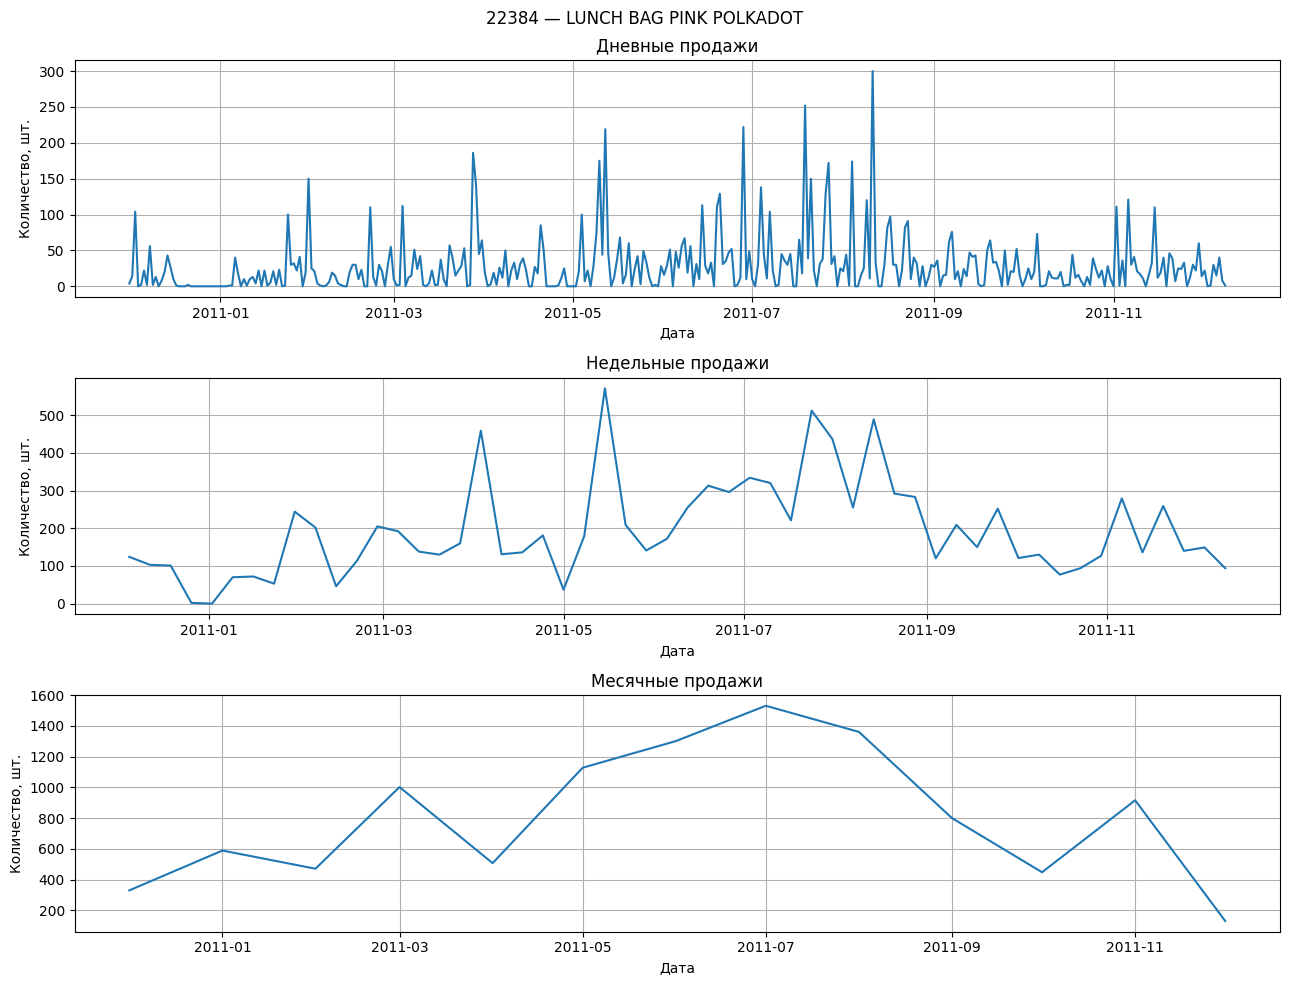

,Число периодов,Всего единиц,Периодов с нулевыми продажами,Пропусков значений
daily,374,10515,82,0
weekly,54,10515,1,0
monthly,13,10515,0,0


In [8]:
def plot_sales_series(series):
    titles = {
        "daily": "Дневные продажи",
        "weekly": "Недельные продажи",
        "monthly": "Месячные продажи",
    }

    fig, axes = plt.subplots(3, 1, figsize=(13, 10))

    for ax, (frequency, ts) in zip(axes, series.items()):
        ax.plot(ts.index, ts.values)
        ax.set_title(titles[frequency])
        ax.set_xlabel("Дата")
        ax.set_ylabel("Количество, шт.")

    fig.suptitle("22384 — LUNCH BAG PINK POLKADOT")
    fig.tight_layout()
    plt.show()

    display(pd.DataFrame({
        frequency: {
            "Число периодов": len(ts),
            "Всего единиц": ts.sum(),
            "Периодов с нулевыми продажами": ts.eq(0).sum(),
            "Пропусков значений": ts.isna().sum(),
        }
        for frequency, ts in series.items()
    }).T)


plot_sales_series(series)

### Описательные статистики и потенциальные выбросы

Для каждой частоты рассчитываются характеристики уровня и разброса продаж. Потенциальные выбросы отмечаются правилом 1,5 IQR. Метод не учитывает тренд
и сезонность, поэтому используется для первичной диагностики: отмеченные значения не считаются ошибками и автоматически не изменяются.

In [9]:
def select_complete_periods(series, start_date, end_date):
    start = start_date.normalize()
    end = end_date.normalize()

    daily = series["daily"]
    weekly = series["weekly"]
    monthly = series["monthly"]

    # Последний день считаем неполным.
    daily = daily.loc[
        (daily.index >= start) & (daily.index < end)
    ]

    # Метка недели - воскресенье; начало - за 6 дней до него.
    weekly = weekly.loc[
        ((weekly.index - pd.Timedelta(days=6)) >= start)
        & (weekly.index < end)
    ]

    month_ends = monthly.index + pd.offsets.MonthEnd(0)
    monthly = monthly.loc[
        (monthly.index >= start) & (month_ends < end)
    ]

    return {"daily": daily, "weekly": weekly, "monthly": monthly}


analysis_series = select_complete_periods(
    series,
    start_date=df["InvoiceDate"].min(),
    end_date=df["InvoiceDate"].max(),
)

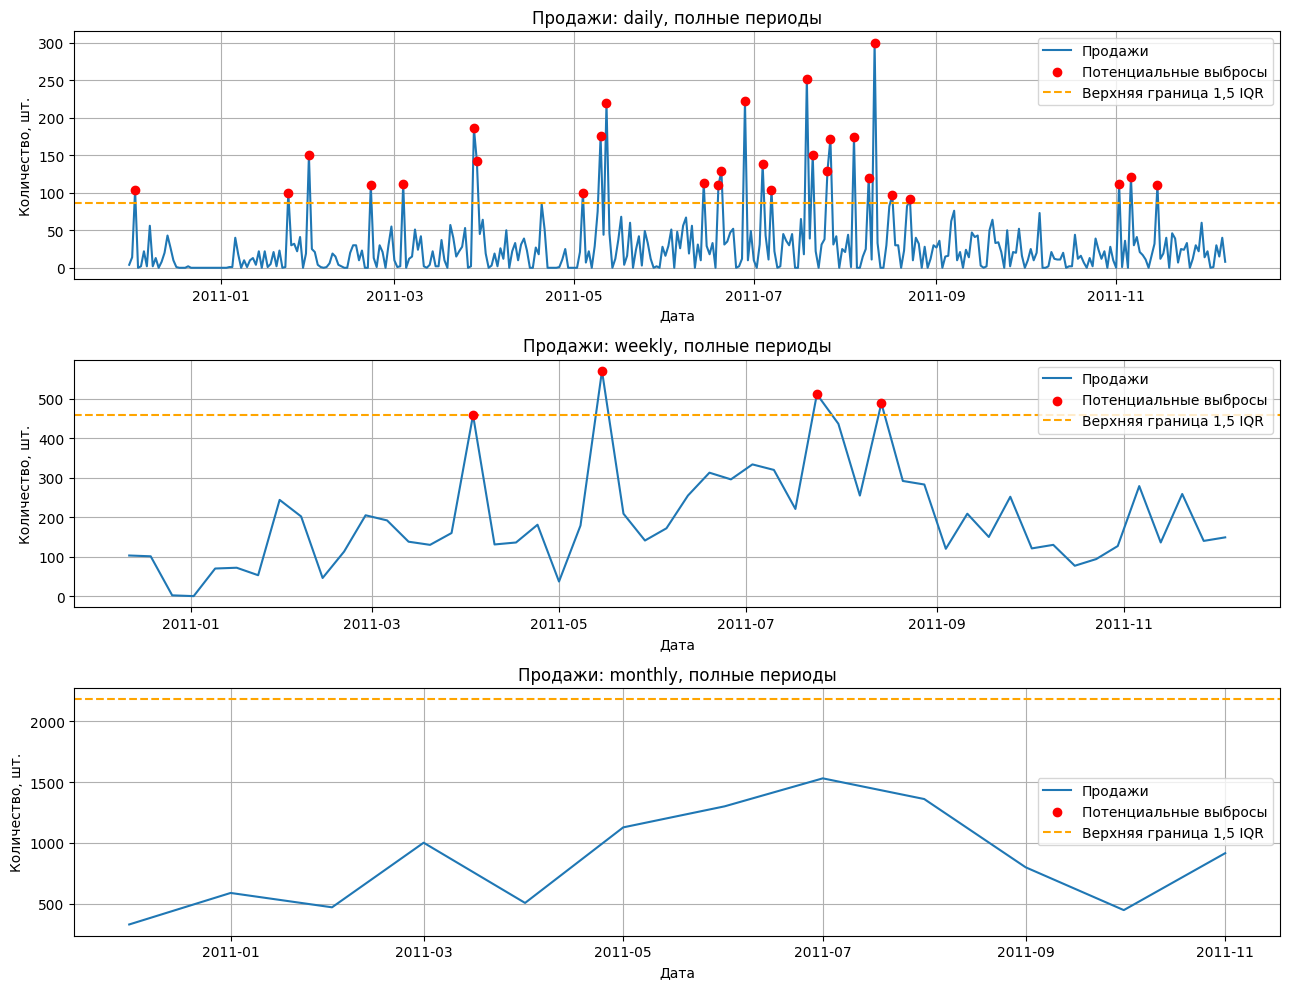

,n,mean,median,std,min,q25,q75,max,zero_pct,iqr_upper,n_flagged
daily,373.0,28.19,18.0,40.38,0.0,1.00,35.00,300.0,21.98,86.00,28.0
weekly,52.0,198.02,166.0,127.56,0.0,120.75,256.00,571.0,1.92,458.88,4.0
monthly,12.0,865.33,858.0,403.86,330.0,498.00,1171.25,1531.0,0.00,2181.12,0.0


Пять дней с наибольшими продажами:


,units
InvoiceDate,
2011-08-11,300
2011-07-19,252
2011-06-28,222
2011-05-12,219
2011-03-28,186


In [10]:
def describe_and_flag_outliers(series):
    summaries = {}
    flagged = {}

    fig, axes = plt.subplots(3, 1, figsize=(13, 10))

    for ax, (frequency, ts) in zip(axes, series.items()):
        q1 = ts.quantile(0.25)
        q3 = ts.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        is_outlier = (ts < lower) | (ts > upper)

        summaries[frequency] = {
            "n": len(ts),
            "mean": ts.mean(),
            "median": ts.median(),
            "std": ts.std(),
            "min": ts.min(),
            "q25": q1,
            "q75": q3,
            "max": ts.max(),
            "zero_pct": ts.eq(0).mean() * 100,
            "iqr_upper": upper,
            "n_flagged": is_outlier.sum(),
        }

        flagged[frequency] = ts.loc[is_outlier]

        ax.plot(ts.index, ts.values, label="Продажи")
        ax.scatter(
            ts.index[is_outlier],
            ts.loc[is_outlier],
            color="red",
            label="Потенциальные выбросы",
            zorder=3,
        )
        ax.axhline(
            upper,
            color="orange",
            linestyle="--",
            label="Верхняя граница 1,5 IQR",
        )
        ax.set_title(f"Продажи: {frequency}, полные периоды")
        ax.set_xlabel("Дата")
        ax.set_ylabel("Количество, шт.")
        ax.legend()

    fig.tight_layout()
    plt.show()

    summary = pd.DataFrame(summaries).T
    display(summary.round(2))

    print("Пять дней с наибольшими продажами:")
    display(series["daily"].nlargest(5).to_frame("units"))

    return summary, flagged


summary, flagged = describe_and_flag_outliers(analysis_series)

Правило 1,5 IQR отметило 28 дневных и 4 недельных значения, на месячной частоте превышений не обнаружено. Эти отметки сами по себе не свидетельствуют об ошибках: распределение продаж асимметрично, содержит нулевые дни, а уровень продаж меняется во времени.

In [11]:
def inspect_peak_days(product, daily, top_n=5):
    cancelled = (
        product["InvoiceNo"]
        .str.upper()
        .str.startswith("C", na=False)
    )

    sales = product.loc[
        product["Quantity"].gt(0)
        & product["UnitPrice"].gt(0)
        & ~cancelled
    ].copy()

    sales["date"] = sales["InvoiceDate"].dt.normalize()
    peak_dates = daily.nlargest(top_n).index

    peaks = (
        sales.loc[sales["date"].isin(peak_dates)]
        .groupby("date")
        .agg(
            total_units=("Quantity", "sum"),
            n_invoices=("InvoiceNo", "nunique"),
            max_line_units=("Quantity", "max"),
        )
        .sort_values("total_units", ascending=False)
    )

    display(peaks)


inspect_peak_days(product, analysis_series["daily"])

,total_units,n_invoices,max_line_units
date,,,
2011-08-11,300,15,200
2011-07-19,252,9,100
2011-06-28,222,5,100
2011-05-12,219,5,100
2011-03-28,186,6,150


Проверка пяти максимальных дней показала, что существенную часть пиков формируют отдельные позиции по 100–200 единиц - т.е. крупные партийные закупки, что может отражать реальную закупку (особенно, если учесть, что они приходятся на весенне-летний "сезон пикников"), но и при этом также и являться потенциальными выбросами: без дополнительных сведений нельзя обоснованно признать их ошибками и выбрать способ исправления. В связи с чем принято решение оставить точки для анализа, т.к. четкая причина неизвестна и явного свидетельства 100% выбросов нет

### Декомпозиция и исследование сезонности

Для дневного ряда применяется аддитивная STL-декомпозиция:

Продажи = тренд + сезонная компонента + остаток.

Выбран период 7 дней, поскольку данные имеют календарную недельную структуру: во все субботы операции отсутствуют. Используется робастный
вариант STL, уменьшающий влияние отдельных пиков на оценку компонентов без изменения исходных продаж.

Само выделение сезонной компоненты при заданном периоде не доказывает наличие сезонности. Поэтому дополнительно сравниваются средние
и медианные продажи по дням недели.

Годовую сезонность надёжно оценить нельзя, т.к. доступен только один год наблюдений

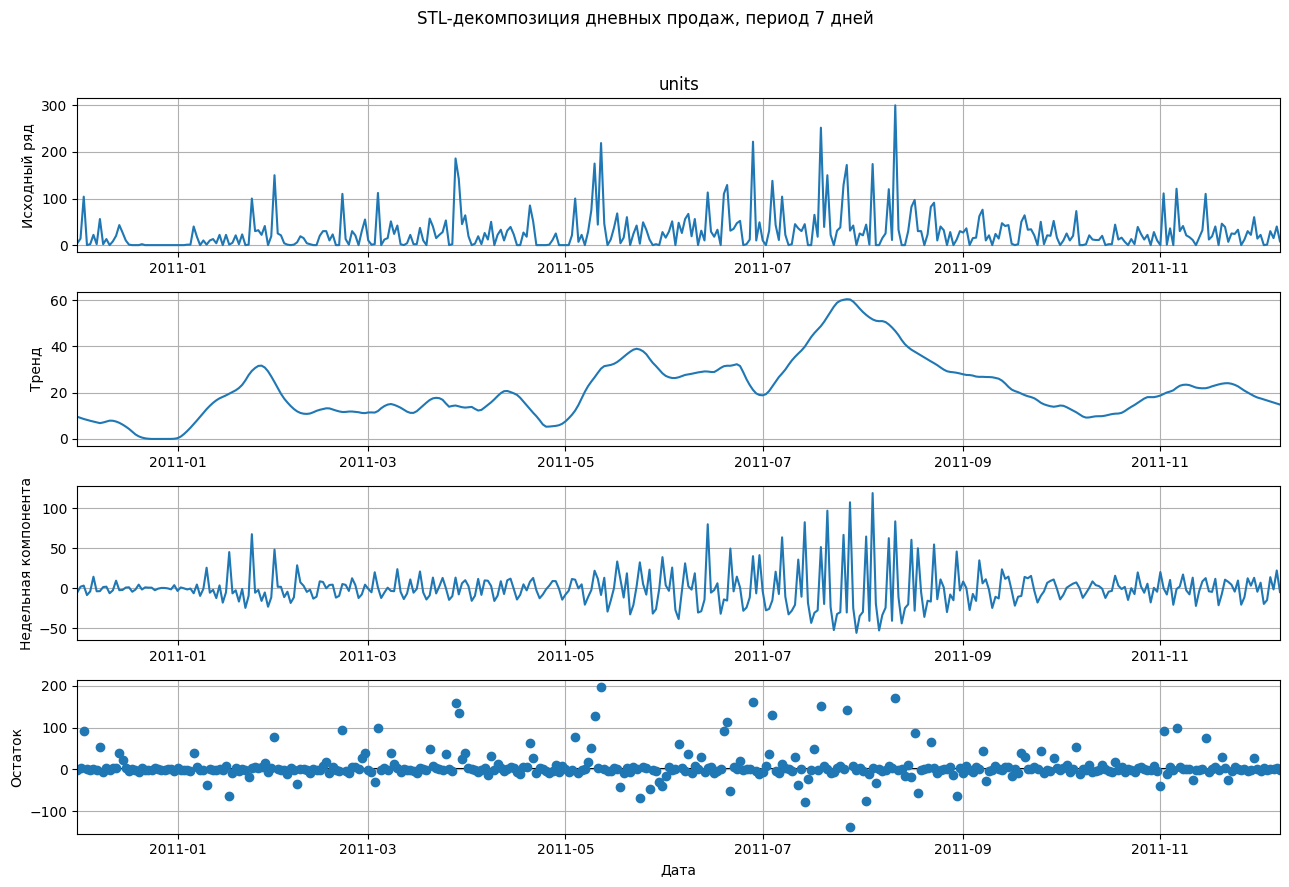

,count,mean,median,std
Пн,53,35.06,22.0,41.63
Вт,53,46.25,28.0,55.70
Ср,54,32.02,24.0,32.69
Чт,54,39.15,24.5,55.29
Пт,53,25.45,22.0,23.69
Сб,53,0.00,0.0,0.00
Вс,53,19.11,12.0,25.28


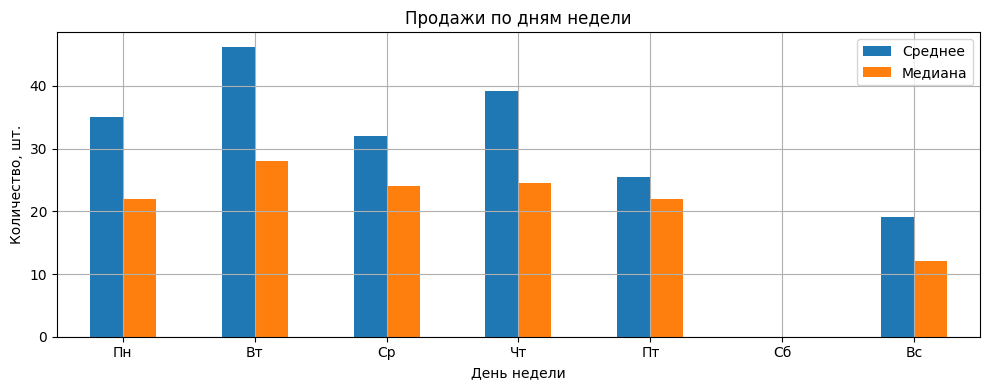

In [12]:
from statsmodels.tsa.seasonal import STL


def analyze_weekly_seasonality(daily):
    result = STL(daily, period=7, robust=True).fit()

    fig = result.plot()
    fig.set_size_inches(13, 9)

    labels = [
        "Исходный ряд",
        "Тренд",
        "Недельная компонента",
        "Остаток",
    ]

    for ax, label in zip(fig.axes, labels):
        ax.set_ylabel(label)

    fig.axes[-1].set_xlabel("Дата")
    fig.suptitle("STL-декомпозиция дневных продаж, период 7 дней")
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

    weekday_stats = (
        daily.to_frame("units")
        .assign(weekday=daily.index.dayofweek)
        .groupby("weekday")["units"]
        .agg(["count", "mean", "median", "std"])
        .reindex(range(7))
    )

    weekday_stats.index = [
        "Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"
    ]

    display(weekday_stats.round(2))

    ax = weekday_stats[["mean", "median"]].plot(
        kind="bar",
        figsize=(10, 4),
        rot=0,
    )
    ax.set_title("Продажи по дням недели")
    ax.set_xlabel("День недели")
    ax.set_ylabel("Количество, шт.")
    ax.legend(["Среднее", "Медиана"])
    plt.tight_layout()
    plt.show()

    return result, weekday_stats


stl_result, weekday_stats = analyze_weekly_seasonality(
    analysis_series["daily"]
)

### Выводы по декомпозиции

STL-разложение показывает изменение базового уровня продаж: летом он выше, с максимумом примерно в июле–августе и последующим снижением. 

Выявлена недельная календарная структура зарегистрированных продаж: во все субботы операции отсутствуют, в воскресенье продажи ниже, чем в остальные дни. Наибольшие среднее и медиана наблюдаются во вторник — 46,25 и 28 единиц соответственно. При этом недельная компонента STL меняется во времени и не рассматривается как неизменный календарный профиль.

В остатках сохраняются отдельные крупные отклонения, не объяснённые оценёнными трендом и недельной компонентой. Они не доказывают ошибочность исходных операций, но потенциальные выбросы сохраняются

### Проверка стационарности

Для дневного, недельного и месячного рядов на полных периодах применяются тесты ADF и KPSS с константой, без детерминированного линейного тренда. Уровень значимости — 0,05.

Нулевая гипотеза ADF — наличие единичного корня; нулевая гипотеза KPSS — стационарность относительно постоянного уровня.
Результаты рассматриваются совместно с графиками и календарной структурой данных, поскольку тесты не проверяют все свойства стационарности.

Месячный ряд содержит только 12 наблюдений, поэтому результаты его тестирования имеют ограниченную информативность.

In [13]:
from statsmodels.tsa.stattools import adfuller, kpss


def test_stationarity(series):
    rows = []

    for name, ts in series.items():
        values = ts.dropna().astype(float)

        adf_result = adfuller(
            values,
            regression="c",
            autolag="AIC",
        )

        kpss_result = kpss(
            values,
            regression="c",
            nlags="auto",
        )

        rows.append({
            "series": name,
            "n": len(values),
            "ADF_stat": adf_result[0],
            "ADF_p": adf_result[1],
            "ADF_lags": adf_result[2],
            "KPSS_stat": kpss_result[0],
            "KPSS_p": kpss_result[1],
            "KPSS_lags": kpss_result[2],
        })

    result = pd.DataFrame(rows).set_index("series")
    display(result.round(4))

    return result


import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning

with warnings.catch_warnings():
    warnings.simplefilter("ignore", InterpolationWarning)
    stationarity_results = test_stationarity(analysis_series)

,n,ADF_stat,ADF_p,ADF_lags,KPSS_stat,KPSS_p,KPSS_lags
series,,,,,,,
daily,373,-4.1440,0.0008,7,0.8009,0.0100,4
weekly,52,-4.6729,0.0001,0,0.3973,0.0783,3
monthly,12,-3.6566,0.0048,4,0.2536,0.1000,1


ADF отвергает гипотезу единичного корня для всех трёх частот.

Для дневного ряда KPSS также отвергает стационарность относительно постоянного уровня, т.е. результаты расходятся и не позволяют признать его
стационарным

Для недельного ряда результаты согласуются со стационарностью при уровне значимости 5%. Для месячного ряда вывод ограничен малым объёмом выборки — 12 наблюдений.

### Дополнительная диагностика и преобразования

Изменение уровня и разброса исследуется с помощью скользящих среднего и стандартного отклонения: окно составляет 28 дней для дневного ряда и 8 недель для недельного. Окна выбраны для описательной диагностики, колебания этих оценок сами по себе не доказывают нестационарность.

Для дневного ряда проверяется сезонная разность с лагом 7, мотивированная недельной календарной структурой и результатом KPSS.
Для недельного ряда обычная разность рассматривается как дополнительный вариант из-за визуальных изменений уровня на графике, несмотря на неотвержение стационарности тестом KPSS при уровне 5%.

In [14]:
def make_differences(series):
    return {
        "daily_diff7": series["daily"].diff(7).dropna(),
        "weekly_diff1": series["weekly"].diff(1).dropna(),
    }


transformed_series = make_differences(analysis_series)

comparison_series = {
    "daily_original": analysis_series["daily"],
    "daily_diff7": transformed_series["daily_diff7"],
    "weekly_original": analysis_series["weekly"],
    "weekly_diff1": transformed_series["weekly_diff1"],
}

with warnings.catch_warnings():
    warnings.simplefilter("ignore", InterpolationWarning)
    comparison_results = test_stationarity(comparison_series)

,n,ADF_stat,ADF_p,ADF_lags,KPSS_stat,KPSS_p,KPSS_lags
series,,,,,,,
daily_original,373,-4.1440,0.0008,7,0.8009,0.0100,4
daily_diff7,366,-8.6522,0.0000,13,0.0226,0.1000,3
weekly_original,52,-4.6729,0.0001,0,0.3973,0.0783,3
weekly_diff1,51,-5.4530,0.0000,4,0.2286,0.1000,21


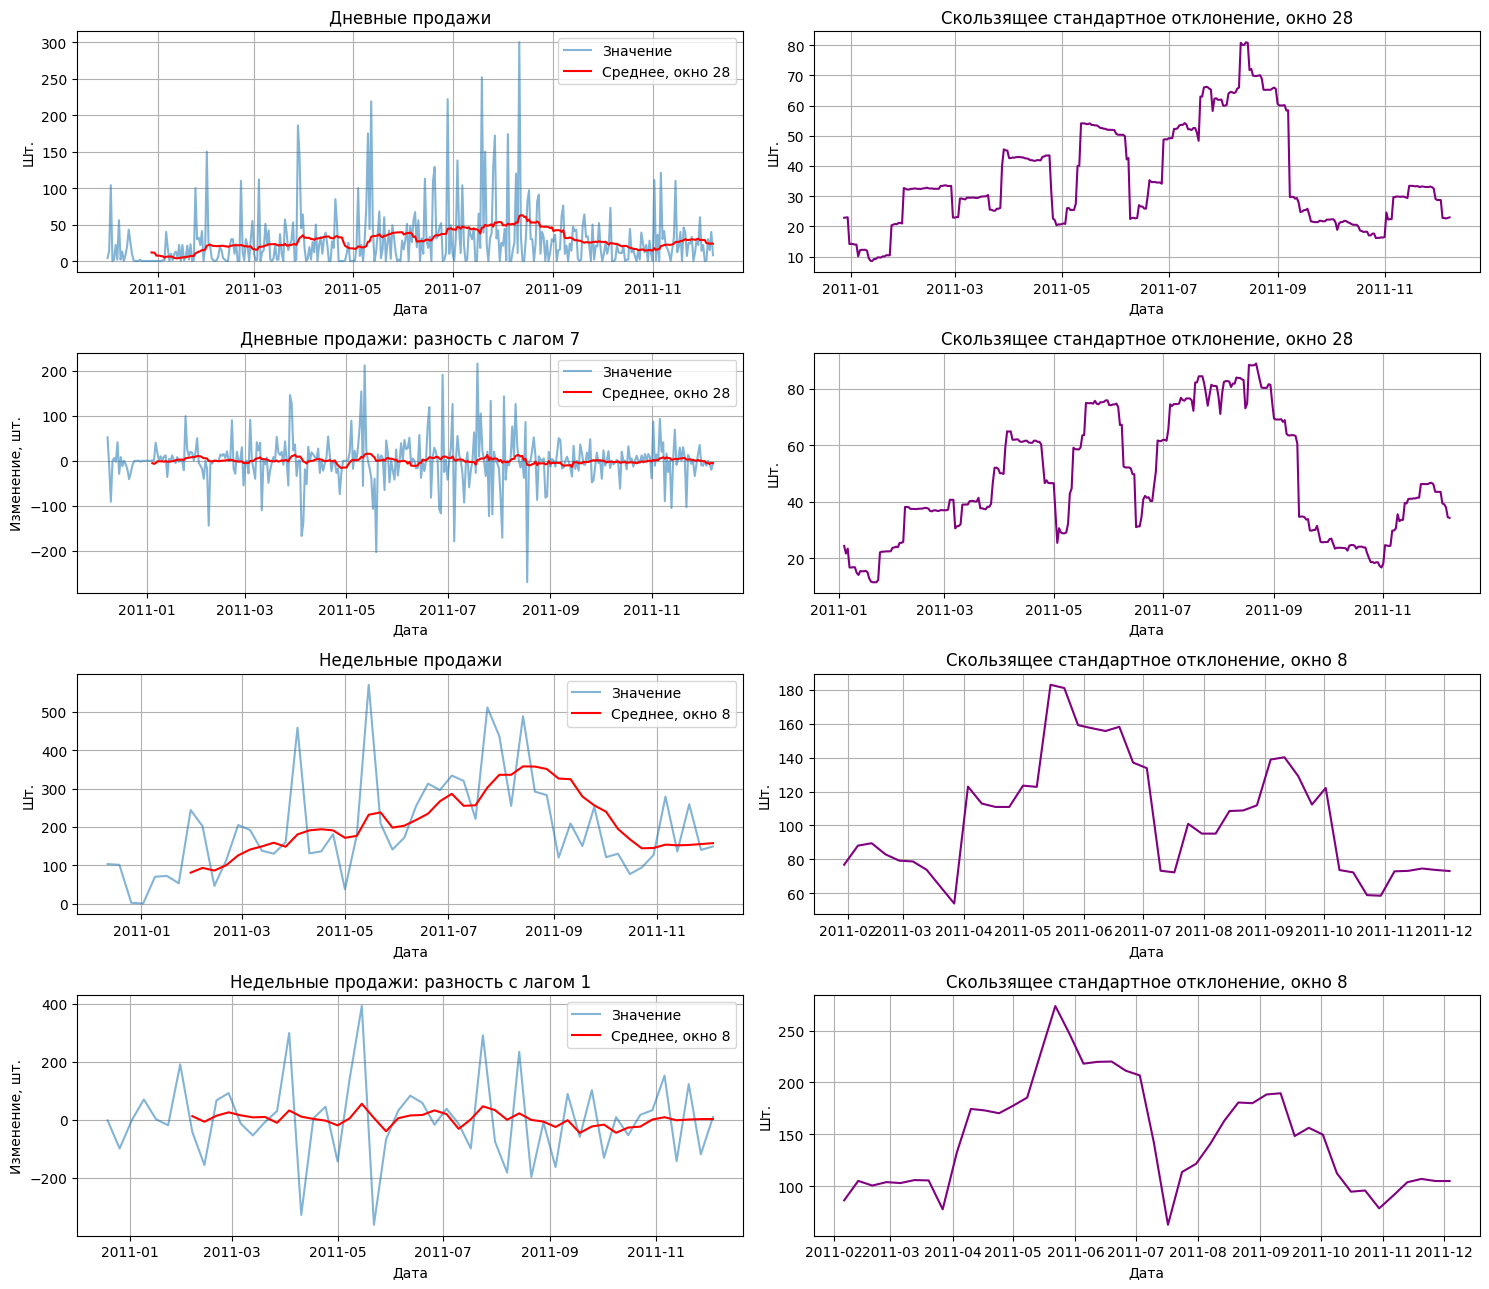

In [15]:
def plot_stationarity_diagnostics(series):
    settings = {
        "daily_original": ("Дневные продажи", 28),
        "daily_diff7": ("Дневные продажи: разность с лагом 7", 28),
        "weekly_original": ("Недельные продажи", 8),
        "weekly_diff1": ("Недельные продажи: разность с лагом 1", 8),
    }

    fig, axes = plt.subplots(
        4, 2,
        figsize=(15, 13),
    )

    for row, (name, ts) in enumerate(series.items()):
        title, window = settings[name]

        rolling_mean = ts.rolling(window).mean()
        rolling_std = ts.rolling(window).std()

        ax = axes[row, 0]
        ax.plot(
            ts.index, ts.values,
            alpha=0.55, label="Значение",
        )
        ax.plot(
            rolling_mean.index, rolling_mean.values,
            color="red", label=f"Среднее, окно {window}",
        )
        ax.set_title(title)
        ax.set_ylabel("Шт." if "original" in name else "Изменение, шт.")
        ax.legend()

        ax = axes[row, 1]
        ax.plot(
            rolling_std.index, rolling_std.values,
            color="purple",
        )
        ax.set_title(f"Скользящее стандартное отклонение, окно {window}")
        ax.set_ylabel("Шт.")

    for ax in axes.flat:
        ax.set_xlabel("Дата")

    plt.tight_layout()
    plt.show()


plot_stationarity_diagnostics(comparison_series)

### Результаты преобразований

После сезонного дифференцирования дневного ряда с лагом 7 и обычного дифференцирования недельного ряда ADF отвергает единичный корень (p < 0,0001), а KPSS не отвергает стационарность относительно уровня (p ≥ 0,10).

Скользящие средние преобразованных рядов колеблются около нуля, однако скользящие стандартные отклонения остаются неоднородными. Следовательно, преобразования стабилизировали уровень, но постоянство дисперсии не установлено. Результаты тестов не рассматриваются как доказательство полной слабой стационарности.

Недельная разность является дополнительным вариантом анализа: необходимость её применения не установлена однозначно.

In [16]:
def make_log_difference(daily):
    return np.log1p(daily).diff(7).dropna()


daily_log_diff7 = make_log_difference(analysis_series["daily"])

with warnings.catch_warnings():
    warnings.simplefilter("ignore", InterpolationWarning)
    log_results = test_stationarity({
        "daily_log_diff7": daily_log_diff7,
    })

,n,ADF_stat,ADF_p,ADF_lags,KPSS_stat,KPSS_p,KPSS_lags
series,,,,,,,
daily_log_diff7,366,-7.8719,0.0,13,0.0208,0.1,6


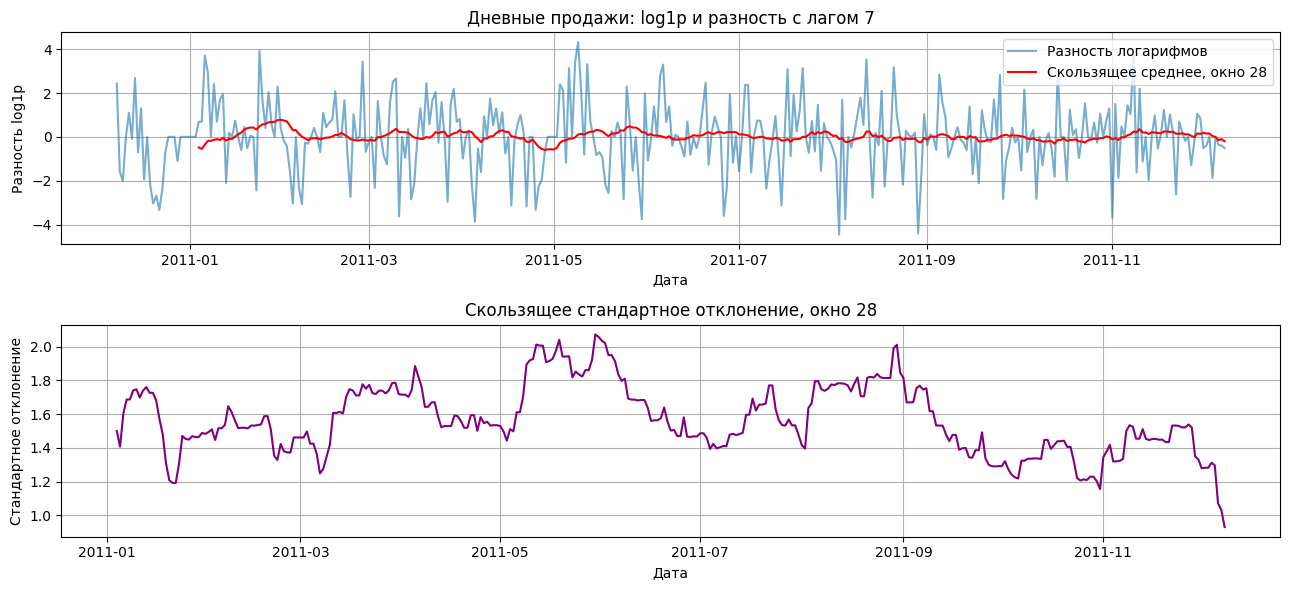

In [17]:
def plot_log_difference(ts, window=28):
    fig, axes = plt.subplots(2, 1, figsize=(13, 6))

    axes[0].plot(ts.index, ts.values, alpha=0.6, label="Разность логарифмов")
    axes[0].plot(
        ts.rolling(window).mean(),
        color="red",
        label=f"Скользящее среднее, окно {window}",
    )
    axes[0].set_title("Дневные продажи: log1p и разность с лагом 7")
    axes[0].set_ylabel("Разность log1p")
    axes[0].legend()

    axes[1].plot(ts.rolling(window).std(), color="purple")
    axes[1].set_title(f"Скользящее стандартное отклонение, окно {window}")
    axes[1].set_ylabel("Стандартное отклонение")

    for ax in axes:
        ax.set_xlabel("Дата")

    plt.tight_layout()
    plt.show()


plot_log_difference(daily_log_diff7)

### Итог по преобразованиям

Для дневного ряда рассмотрено преобразование z_t = log(1 + y_t) − log(1 + y_{t−7}).
Логарифм допускает нулевые продажи и уменьшает влияние крупных значений, а сезонная разность сравнивает одинаковые дни соседних недель.

После преобразования ADF отвергает наличие единичного корня (p < 0,0001), а KPSS не отвергает стационарность относительно уровня (p >= 0,10). Скользящее среднее колеблется около нуля? выраженное увеличение разброса летом ослабло по сравнению с разностью без логарифма.

Преобразование принято как рабочий вариант стабилизации дневного ряда. Полная слабая стационарность не считается доказанной: разброс продолжает
меняться, а нулевые субботние значения сохраняют календарную структуру. При дальнейшем прогнозировании следует учитывать день недели.

Для недельного ряда обычная разность исследована как дополнительный вариан, её необходимость однозначно не установлена. Месячный ряд не преобразуется из-за малого объёма выборки и отсутствия убедительных оснований для выбора преобразования.

## Итоговые выводы

Для товара 22384 - LUNCH BAG PINK POLKADOT построены дневной, недельный и месячный ряды количества проданных единиц. За весь период зарегистрировано 10 515 единиц в положительных операциях без отмен.

В необходимых для построения ряда полях выбранного товара пропусков нет. Отсутствие операций по календарным дням исследовано отдельно:
оно преимущественно связано с субботами и предполагаемыми праздничными перерывами. При допущении полноты выгрузки такие дни представлены нулями.
Полные дубликаты сохранены, поскольку их ошибочность не установлена.

Распределение продаж асимметрично: среднее дневное количество на полных днях составляет 28,19 единицы, медиана — 18. Правило 1,5 IQR отметило 28 дневных и 4 недельных значения. Крупные позиции объясняют существенную часть исследованных пиков, но не позволяют подтвердить или опровергнуть корректность операций. Потенциальные выбросы сохранены без изменения.

STL-декомпозиция выявила повышение базового уровня летом и последующее снижение, что согласуется с логикой повышенной закупки ланчбоксов под "сезон пикников", особенно актуально для культуры в Великобритании. Наблюдается недельная календарная структура: нулевые продажи по субботам и более низкие продажи по воскресеньям.

Для исходного дневного ряда ADF отвергает единичный корень, но KPSS отвергает стационарность относительно постоянного уровня.
После log1p и сезонной разности с лагом 7 средний уровень стабилизируется, а выраженная неоднородность разброса ослабевает; результаты ADF и KPSS
согласуются со стационарностью относительно уровня. Полная слабая стационарность не доказана, календарная структура частично сохраняется.

Для исходного недельного ряда результаты тестов не дают однозначных оснований для преобразования, несмотря на видимые изменения уровня.